In [ ]:
# Airbus ship / no-ship: train the models and download them

**Session options (right-hand panel) before running**
1. **Add Data** → *Airbus Ship Detection Challenge* (accept the competition rules if asked)
2. **Accelerator** → GPU (T4 or P100)
3. **Internet** → On (for `pip install mahotas` and the ImageNet DenseNet-169 weights)

Run the cells top to bottom. Cells 1-2 only define things; **training happens in cells 3-5**; **cell 6 packages the
trained models into `airbus_models.zip`**, which you download from the *Output* panel (or the link it prints).
If the kernel restarts, re-run cells 1-2 and then only the stage you need.

In [5]:
!pip install -q mahotas

In [6]:
# 1) SETTINGS: the only cell you normally edit
import glob, os, types, torch
csv = glob.glob("/kaggle/input/**/train_ship_segmentations_v2.csv", recursive=True)
assert csv, "Airbus dataset not attached: Add Data -> search 'Airbus Ship Detection Challenge'"
DATA = os.path.dirname(csv[0])
assert os.path.isdir(f"{DATA}/train_v2"), f"no train_v2/ folder in {DATA}"
cfg = types.SimpleNamespace(
    data=DATA, csv="train_ship_segmentations_v2.csv", img_dir="train_v2",
    out="/kaggle/temp/exp1",                    # cache + results (not saved with the notebook)
    model_dir="/kaggle/working/airbus_models",  # trained weights end up here
    n_train=7000, n_dev=3000, n_test=5000, seed=0,
    epochs=30, batch_size=64, lr=1e-3, workers=4, jobs=4, raw_size=32,
    tl_weights="imagenet")                      # "none" = skip the pretrained weights
print("data:", DATA, "| gpu:", torch.cuda.is_available(), "| cpus:", os.cpu_count())

data: /kaggle/input/competitions/airbus-ship-detection | gpu: True | cpus: 4


In [17]:
# 2) DEFINITIONS (pipeline functions; nothing runs here)
import json
import time
import warnings
from pathlib import Path

import cv2
import matplotlib
import numpy as np
import pandas as pd

matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
from joblib import Parallel, delayed  # noqa: E402


IMG = 256
THRESHOLDS = np.round(np.arange(0.1, 0.91, 0.1), 1)


# --------------------------------------------------------------------------- #
# Stage 1: prepare
# --------------------------------------------------------------------------- #
def prepare(a):
    out = Path(a.out); out.mkdir(parents=True, exist_ok=True)
    df = pd.read_csv(Path(a.data) / a.csv)
    lab = (df.groupby("ImageId")["EncodedPixels"]
             .apply(lambda s: int(s.notna().any())).reset_index(name="has_ship"))
    n_total = a.n_train + a.n_dev + a.n_test
    print(f"{len(lab)} unique tiles, {lab.has_ship.mean():.3f} contain ships; sampling {n_total}")
    order = np.random.default_rng(a.seed).permutation(len(lab))   # uniform random: keeps imbalance
    images = np.lib.format.open_memmap(out / "images.npy", mode="w+", dtype=np.uint8,
                                       shape=(n_total, IMG, IMG, 3))
    ys, ids = [], []
    for idx in order:
        if len(ys) == n_total:
            break
        row = lab.iloc[idx]
        im = cv2.imread(str(Path(a.data) / a.img_dir / row.ImageId))
        if im is None:                                   # a few Airbus tiles are corrupt
            continue
        im = cv2.resize(cv2.cvtColor(im, cv2.COLOR_BGR2RGB), (IMG, IMG), interpolation=cv2.INTER_AREA)
        images[len(ys)] = im
        ys.append(int(row.has_ship)); ids.append(row.ImageId)
    if len(ys) < n_total:
        raise SystemExit(f"only {len(ys)} readable tiles, need {n_total}")
    images.flush()
    np.save(out / "labels.npy", np.array(ys, dtype=np.int64))
    json.dump({"ids": ids, "n_train": a.n_train, "n_dev": a.n_dev, "n_test": a.n_test},
              open(out / "meta.json", "w"))
    sp = split_idx(a.n_train, a.n_dev, a.n_test)
    for k, v in sp.items():
        print(f"  {k}: {len(v)} tiles, ship fraction {np.mean(np.array(ys)[v]):.3f}")


def split_idx(n_train, n_dev, n_test):
    i = np.arange(n_train + n_dev + n_test)       # sample order is already random
    return {"train": i[:n_train], "dev": i[n_train:n_train + n_dev], "test": i[n_train + n_dev:]}


def load_data(out):
    out = Path(out)
    images = np.load(out / "images.npy", mmap_mode="r")
    y = np.load(out / "labels.npy")
    m = json.load(open(out / "meta.json"))
    return images, y, split_idx(m["n_train"], m["n_dev"], m["n_test"])


# --------------------------------------------------------------------------- #
# Stage 2: classical models
# --------------------------------------------------------------------------- #
def tile_features(rgb):
    """His: HSV 8x8x8 colour histogram; Ha: mean Haralick (13); Hu: Hu moments (7)."""
    import mahotas
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    h = cv2.calcHist([hsv], [0, 1, 2], None, [8, 8, 8], [0, 180, 0, 256, 0, 256])
    cv2.normalize(h, h)
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    try:
        ha = mahotas.features.haralick(gray).mean(axis=0)
    except Exception:                                  # degenerate (constant) tile
        ha = np.zeros(13)
    hu = cv2.HuMoments(cv2.moments(gray)).flatten()
    return h.flatten(), np.nan_to_num(ha), hu


def raw_pixels(rgb, size):
    return cv2.resize(rgb, (size, size), interpolation=cv2.INTER_AREA).astype(np.float32).ravel() / 255.0


def get_features(a, images):
    f = Path(a.out) / "features.npz"
    if f.exists():
        z = np.load(f)
        return {k: z[k] for k in z.files}
    t = time.time()
    res = Parallel(n_jobs=a.jobs)(delayed(tile_features)(np.asarray(images[i]))
                                  for i in range(len(images)))
    feats = {"his": np.stack([r[0] for r in res]), "ha": np.stack([r[1] for r in res]),
             "hu": np.stack([r[2] for r in res])}
    feats["raw"] = np.stack(Parallel(n_jobs=a.jobs)(
        delayed(raw_pixels)(np.asarray(images[i]), a.raw_size) for i in range(len(images))))
    np.savez_compressed(f, **feats)
    print(f"features extracted in {time.time() - t:.0f}s")
    return feats


def classical(a):
    from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.model_selection import StratifiedKFold, cross_val_score
    from sklearn.naive_bayes import GaussianNB
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import MinMaxScaler
    from sklearn.svm import SVC
    warnings.filterwarnings("ignore")

    out = Path(a.out)
    images, y, sp = load_data(out)
    feats = get_features(a, images)
    tr, te = sp["train"], sp["test"]
    print(f"majority-class ('no ship') test accuracy: {1 - y[te].mean():.3f}")

    models = {
        "LDA": lambda: LinearDiscriminantAnalysis(),
        "KNN": lambda: KNeighborsClassifier(n_neighbors=5),
        "NB": lambda: GaussianNB(),
        "RF": lambda: RandomForestClassifier(n_estimators=10, max_depth=5, random_state=a.seed),
        "SVM": lambda: SVC(kernel="rbf"),
    }
    combos = {"His": ["his"], "Ha": ["ha"], "Hu": ["hu"], "His+Ha": ["his", "ha"],
              "Ha+Hu": ["ha", "hu"], "Hu+His": ["hu", "his"], "w/ all": ["his", "ha", "hu"]}
    X = {c: np.hstack([feats[k] for k in ks]) for c, ks in combos.items()}
    X["w/o"] = feats["raw"]                       # no feature engineering: raw pixels

    table = pd.DataFrame(index=list(models), columns=list(X), dtype=float)
    for m, mk in models.items():
        for c, Xc in X.items():
            clf = make_pipeline(MinMaxScaler(), mk()).fit(Xc[tr], y[tr])
            table.loc[m, c] = clf.score(Xc[te], y[te])
        print(m, " ".join(f"{c}={table.loc[m, c]:.2f}" for c in X))
    table.round(3).to_csv(out / "table1_test_accuracy.csv")

    import joblib
    mdir = Path(getattr(a, "model_dir", None) or out / "models"); mdir.mkdir(parents=True, exist_ok=True)
    rf = make_pipeline(MinMaxScaler(), models["RF"]()).fit(X["w/ all"][tr], y[tr])
    joblib.dump({"model": rf, "features": "concat(his[512], ha[13], hu[7]) from tile_features()",
                 "test_acc": float(rf.score(X["w/ all"][te], y[te]))}, mdir / "random_forest.joblib")

    # 10-fold CV with all features (Fig. 5)
    cv = StratifiedKFold(10, shuffle=True, random_state=a.seed)
    scores = {m: cross_val_score(make_pipeline(MinMaxScaler(), mk()), X["w/ all"][tr], y[tr],
                                 cv=cv, n_jobs=a.jobs) for m, mk in models.items()}
    pd.DataFrame(scores).to_csv(out / "cv_scores.csv", index=False)
    fig, ax = plt.subplots(figsize=(5, 3.2))
    ax.boxplot(list(scores.values()), tick_labels=list(scores))
    ax.set_ylabel("10-fold CV accuracy"); ax.grid(axis="y", alpha=0.3)
    savefig(fig, out, "fig5_cv_boxplot.png")
    print({m: f"{s.mean():.3f}+/-{s.std():.3f}" for m, s in scores.items()})


# --------------------------------------------------------------------------- #
# Stage 3: CNNs
# --------------------------------------------------------------------------- #
def build_cnn_stuff():
    """Imports torch lazily so the classical stage works without it."""
    global torch, nn, F, torchvision, Dataset, DataLoader, v2
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    import torchvision
    from torch.utils.data import DataLoader, Dataset
    from torchvision.transforms import v2

    class SimCNN(nn.Module):
        def __init__(self):
            super().__init__()
            ch, layers = [3, 16, 32, 64, 128], []
            for i, o in zip(ch[:-1], ch[1:]):
                layers += [nn.Conv2d(i, o, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2)]
            self.features = nn.Sequential(*layers)
            self.head = nn.Sequential(nn.Flatten(), nn.Linear(128 * 16 * 16, 128),
                                      nn.ReLU(inplace=True), nn.Linear(128, 1))

        def forward(self, x):                      # returns logits
            return self.head(self.features(x)).squeeze(1)

    class TLCNN(nn.Module):
        def __init__(self, pretrained=True):
            super().__init__()
            w = torchvision.models.DenseNet169_Weights.IMAGENET1K_V1 if pretrained else None
            self.backbone = torchvision.models.densenet169(weights=w).features
            for p in self.backbone.parameters():
                p.requires_grad = False
            self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
            self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
            self.bn = nn.BatchNorm2d(1664)
            self.drop = nn.Dropout(0.5)
            self.fc1, self.fc2 = nn.Linear(1664, 128), nn.Linear(128, 1)

        def train(self, mode=True):
            super().train(mode)
            self.backbone.eval()                   # keep frozen BN statistics
            return self

        def forward(self, x):
            with torch.no_grad():
                f = F.relu(self.backbone((x - self.mean) / self.std))
            f = F.adaptive_max_pool2d(self.drop(self.bn(f)), 1).flatten(1)
            return self.fc2(F.relu(self.fc1(f))).squeeze(1)

    class Tiles(Dataset):
        AUG = v2.Compose([
            v2.RandomHorizontalFlip(), v2.RandomVerticalFlip(),
            v2.RandomAffine(degrees=20, translate=(0.1, 0.1), scale=(0.9, 1.1), shear=10),
            v2.ColorJitter(brightness=0.2)])

        def __init__(self, images, y, idx, augment):
            self.images, self.y, self.idx, self.augment = images, y, idx, augment

        def __len__(self):
            return len(self.idx)

        def __getitem__(self, i):
            j = self.idx[i]
            x = torch.from_numpy(np.ascontiguousarray(self.images[j])).permute(2, 0, 1)
            if self.augment:
                x = self.AUG(x)
            return x.float() / 255.0, torch.tensor(float(self.y[j]))

    return SimCNN, TLCNN, Tiles


def n_params(m, trainable=True):
    return sum(p.numel() for p in m.parameters() if (p.requires_grad or not trainable))


def run_epoch(model, loader, dev, opt=None):
    train = opt is not None
    model.train(train)
    use_amp = dev.type == "cuda"                   # fp16 autocast works on Kaggle's T4/P100
    if train and not hasattr(opt, "_scaler"):
        opt._scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    loss_sum = correct = n = 0
    probs = []
    for x, yb in loader:
        x, yb = x.to(dev, non_blocking=True), yb.to(dev, non_blocking=True)
        with torch.set_grad_enabled(train), torch.autocast(dev.type, torch.float16, enabled=use_amp):
            logit = model(x)
        loss = F.binary_cross_entropy_with_logits(logit.float(), yb)
        if train:
            opt.zero_grad(set_to_none=True)
            opt._scaler.scale(loss).backward()
            opt._scaler.step(opt)
            opt._scaler.update()
        p = torch.sigmoid(logit.float())
        probs.append(p.detach().cpu())
        loss_sum += loss.item() * len(yb); correct += ((p > 0.5).float() == yb).sum().item(); n += len(yb)
    return loss_sum / n, correct / n, torch.cat(probs).numpy()


def fit(model, name, loaders, a, dev):
    tr, dv = loaders["train"], loaders["dev"]
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=a.lr)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=2)
    best, best_state, hist = float("inf"), None, []
    for ep in range(1, a.epochs + 1):
        t = time.time()
        tl, ta, _ = run_epoch(model, tr, dev, opt)
        dl, da, _ = run_epoch(model, dv, dev)
        sched.step(dl)
        if dl < best:                              # only keep weights that improve dev loss
            best = dl
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        hist.append(dict(epoch=ep, train_loss=tl, train_acc=ta, dev_loss=dl, dev_acc=da))
        print(f"[{name}] ep {ep:02d}  loss {tl:.3f}/{dl:.3f}  acc {ta:.3f}/{da:.3f}  ({time.time() - t:.0f}s)")
    model.load_state_dict(best_state)
    return hist


def cnn(a):
    SimCNN, TLCNN, Tiles = build_cnn_stuff()
    out = Path(a.out)
    torch.manual_seed(a.seed); np.random.seed(a.seed)
    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("device:", dev)
    images, y, sp = load_data(out)

    def loaders():
        mk = lambda k, aug, shuf: DataLoader(Tiles(images, y, sp[k], aug), batch_size=a.batch_size,
                                             shuffle=shuf, num_workers=a.workers)
        return {"train": mk("train", True, True), "dev": mk("dev", False, False),
                "test": mk("test", False, False)}

    results, hists, curves = {}, {}, {}
    for name, ctor, expected in [("TL-CNN", lambda: TLCNN(a.tl_weights == "imagenet"), 216_577),
                                 ("SIM-CNN", SimCNN, 4_292_001)]:
        try:
            model = ctor().to(dev)
        except Exception as e:
            raise RuntimeError(f"could not build {name} ({type(e).__name__}: {e}). TL-CNN downloads the "
                               "ImageNet DenseNet-169 weights: on Kaggle turn Internet ON in the session "
                               "options (or pass tl_weights='none' to skip the pretrained weights).") from e
        assert n_params(model) == expected, (name, n_params(model), expected)
        print(f"{name}: {n_params(model):,} trainable parameters (matches paper)")
        ld = loaders()
        hists[name] = fit(model, name, ld, a, dev)
        _, _, p_dev = run_epoch(model, ld["dev"], dev)
        _, _, p_test = run_epoch(model, ld["test"], dev)
        yd, yt = y[sp["dev"]], y[sp["test"]]
        dev_acc = [float(((p_dev > t) == yd).mean()) for t in THRESHOLDS]
        thr = float(THRESHOLDS[int(np.argmax(dev_acc))])   # imbalance-aware threshold moving
        pred = p_test > thr
        tn, fp = int(((~pred) & (yt == 0)).sum()), int((pred & (yt == 0)).sum())
        fn, tp = int(((~pred) & (yt == 1)).sum()), int((pred & (yt == 1)).sum())
        results[name] = dict(
            threshold=thr, test_acc=float((pred == yt).mean()),
            test_acc_at_0_5=float(((p_test > 0.5) == yt).mean()),
            precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1),
            specificity=tn / max(tn + fp, 1),
            confusion_norm=[[tn / max(tn + fp, 1), fp / max(tn + fp, 1)],
                            [fn / max(tp + fn, 1), tp / max(tp + fn, 1)]],
            dev_acc_by_threshold=dict(zip(map(str, THRESHOLDS), dev_acc)))
        curves[name] = dev_acc
        mdir = Path(getattr(a, "model_dir", None) or out / "models"); mdir.mkdir(parents=True, exist_ok=True)
        torch.save({"arch": "TLCNN" if name == "TL-CNN" else "SimCNN",
                    "state_dict": {k: v.detach().cpu() for k, v in model.state_dict().items()},
                    "threshold": thr, "img_size": IMG, "test_acc": results[name]["test_acc"],
                    "input": "RGB image resized to 256x256, float32 in [0,1] (ImageNet normalisation "
                             "for TL-CNN happens inside the model); output = sigmoid(logit) = P(ship)"},
                   mdir / f"{name.lower().replace('-', '_')}.pth")
        print(f"{name}: threshold {thr}  test acc {results[name]['test_acc']:.3f}  "
              f"P {results[name]['precision']:.2f} R {results[name]['recall']:.2f} "
              f"spec {results[name]['specificity']:.2f}")
        del model

    json.dump({"history": hists, "results": results}, open(out / "cnn_results.json", "w"), indent=1)
    plot_cnn(out, hists, curves, results)


def plot_cnn(out, hists, curves, results):
    # Fig. 6: training loss / accuracy
    fig, ax = plt.subplots(figsize=(5.5, 3.4)); ax2 = ax.twinx()
    for name, c in [("TL-CNN", "tab:blue"), ("SIM-CNN", "tab:gray")]:
        h = hists[name]; e = [r["epoch"] for r in h]
        ax.plot(e, [r["train_loss"] for r in h], c=c, label=f"{name} loss")
        ax2.plot(e, [r["train_acc"] for r in h], c=c, ls="--", label=f"{name} acc.")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Binary cross-entropy"); ax2.set_ylabel("Accuracy")
    l1, l2 = ax.get_legend_handles_labels(), ax2.get_legend_handles_labels()
    ax.legend(l1[0] + l2[0], l1[1] + l2[1], fontsize=7, ncol=2)
    savefig(fig, out, "fig6_training_curves.png")
    # Fig. 7: threshold scan
    fig, ax = plt.subplots(figsize=(5, 3.2))
    for name, accs in curves.items():
        ax.plot(THRESHOLDS, accs, "-o", ms=3, label=name)
        ax.plot(results[name]["threshold"], max(accs), "ro")
    ax.set_xlabel("Threshold"); ax.set_ylabel("Dev accuracy"); ax.legend(); ax.grid(alpha=0.3)
    savefig(fig, out, "fig7_threshold_scan.png")
    # Fig. 8: confusion matrices
    fig, axs = plt.subplots(1, 2, figsize=(6, 3))
    for ax, name in zip(axs, results):
        m = np.array(results[name]["confusion_norm"])
        ax.imshow(m, cmap="Blues", vmin=0, vmax=1)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{m[i, j]:.2f}", ha="center", va="center",
                        color="white" if m[i, j] > 0.5 else "black")
        ax.set_xticks([0, 1], ["no_ship", "has_ship"]); ax.set_yticks([0, 1], ["no_ship", "has_ship"])
        ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(name)
    savefig(fig, out, "fig8_confusion.png")


def savefig(fig, out, name):
    d = Path(out) / "figures"; d.mkdir(exist_ok=True)
    fig.tight_layout(); fig.savefig(d / name, dpi=200); plt.close(fig)


In [18]:
# 3) sample 7k/3k/5k tiles uniformly at random, resize to 256x256, cache as .npy (~3 GB)
prepare(cfg)

192556 unique tiles, 0.221 contain ships; sampling 15000
  train: 7000 tiles, ship fraction 0.219
  dev: 3000 tiles, ship fraction 0.223
  test: 5000 tiles, ship fraction 0.216


In [19]:
# 4) classical models: Table 1 ablation + CV box plot; saves random_forest.joblib
classical(cfg)

features extracted in 67s
majority-class ('no ship') test accuracy: 0.784
LDA His=0.78 Ha=0.81 Hu=0.78 His+Ha=0.82 Ha+Hu=0.81 Hu+His=0.78 w/ all=0.83 w/o=0.72
KNN His=0.79 Ha=0.84 Hu=0.74 His+Ha=0.82 Ha+Hu=0.84 Hu+His=0.79 w/ all=0.82 w/o=0.78
NB His=0.49 Ha=0.68 Hu=0.23 His+Ha=0.50 Ha+Hu=0.28 Hu+His=0.48 w/ all=0.48 w/o=0.45
RF His=0.87 Ha=0.82 Hu=0.78 His+Ha=0.87 Ha+Hu=0.83 Hu+His=0.87 w/ all=0.87 w/o=0.79
SVM His=0.80 Ha=0.82 Hu=0.78 His+Ha=0.83 Ha+Hu=0.82 Hu+His=0.80 w/ all=0.83 w/o=0.78
{'LDA': '0.831+/-0.013', 'KNN': '0.820+/-0.012', 'NB': '0.557+/-0.147', 'RF': '0.871+/-0.011', 'SVM': '0.826+/-0.007'}


In [20]:
# 5) CNNs: trains TL-CNN and SIM-CNN, picks the threshold on the dev set, saves tl_cnn.pth and sim_cnn.pth
cnn(cfg)

device: cuda
Downloading: "https://download.pytorch.org/models/densenet169-b2777c0a.pth" to /root/.cache/torch/hub/checkpoints/densenet169-b2777c0a.pth


100%|██████████| 54.7M/54.7M [00:00<00:00, 108MB/s] 


TL-CNN: 216,577 trainable parameters (matches paper)
[TL-CNN] ep 01  loss 0.447/0.487  acc 0.841/0.833  (31s)
[TL-CNN] ep 02  loss 0.255/0.244  acc 0.907/0.930  (29s)
[TL-CNN] ep 03  loss 0.239/0.251  acc 0.912/0.932  (30s)
[TL-CNN] ep 04  loss 0.229/0.300  acc 0.919/0.917  (31s)
[TL-CNN] ep 05  loss 0.226/0.277  acc 0.917/0.924  (32s)
[TL-CNN] ep 06  loss 0.204/0.276  acc 0.925/0.915  (31s)
[TL-CNN] ep 07  loss 0.200/0.284  acc 0.926/0.918  (31s)
[TL-CNN] ep 08  loss 0.209/0.243  acc 0.924/0.929  (32s)
[TL-CNN] ep 09  loss 0.199/0.264  acc 0.928/0.927  (31s)
[TL-CNN] ep 10  loss 0.203/0.293  acc 0.927/0.915  (32s)
[TL-CNN] ep 11  loss 0.206/0.247  acc 0.926/0.931  (32s)
[TL-CNN] ep 12  loss 0.199/0.286  acc 0.927/0.919  (32s)
[TL-CNN] ep 13  loss 0.192/0.282  acc 0.932/0.912  (32s)
[TL-CNN] ep 14  loss 0.194/0.244  acc 0.929/0.934  (32s)
[TL-CNN] ep 15  loss 0.186/0.247  acc 0.931/0.929  (31s)
[TL-CNN] ep 16  loss 0.187/0.229  acc 0.930/0.934  (31s)
[TL-CNN] ep 17  loss 0.190/0.252  a

     0.0 MB  cnn_results.json
     0.0 MB  cv_scores.csv
     0.0 MB  figures/fig5_cv_boxplot.png
     0.1 MB  figures/fig6_training_curves.png
     0.0 MB  figures/fig7_threshold_scan.png
     0.0 MB  figures/fig8_confusion.png
     0.1 MB  random_forest.joblib
    17.2 MB  sim_cnn.pth
     0.0 MB  table1_test_accuracy.csv
    51.8 MB  tl_cnn.pth


,threshold,test_acc,test_acc_at_0_5,precision,recall,specificity
TL-CNN,0.7,0.9392,0.929,0.932222,0.775416,0.984431
SIM-CNN,0.5,0.9212,0.9212,0.839921,0.785582,0.958652


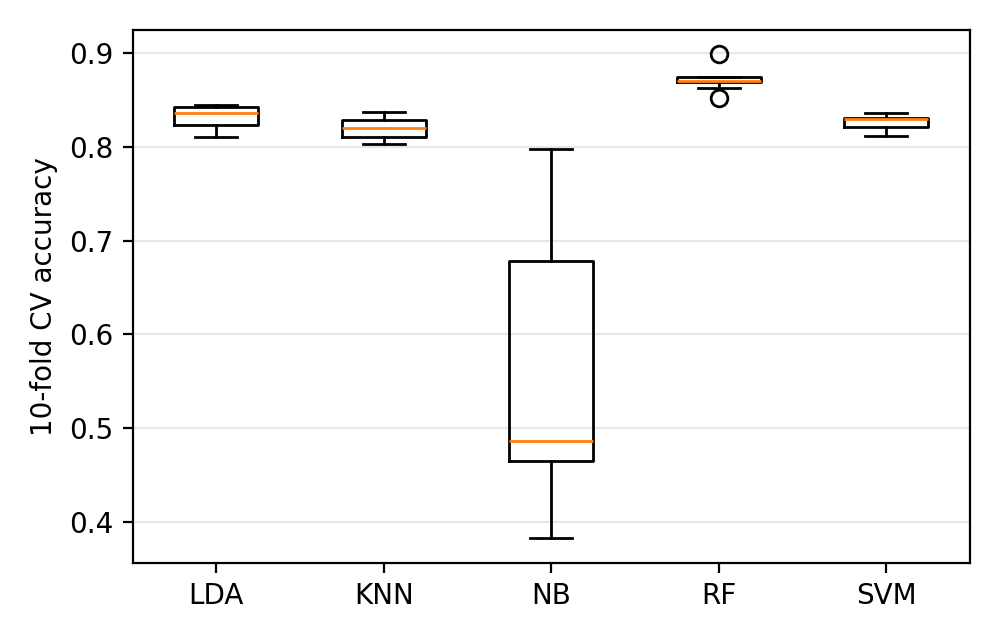

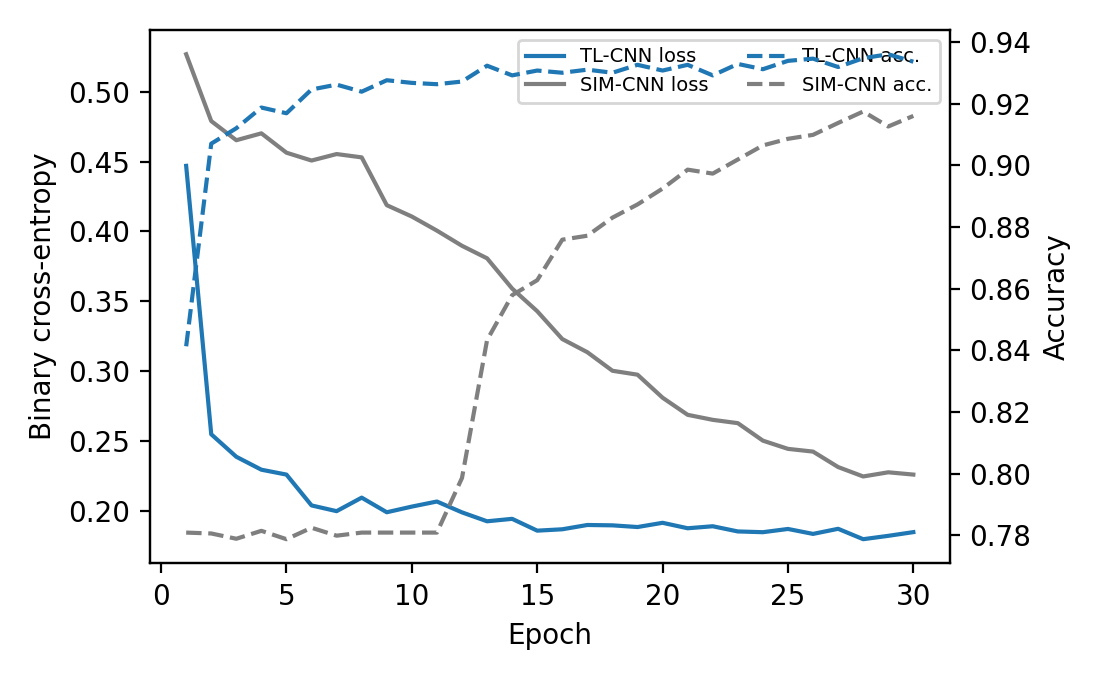

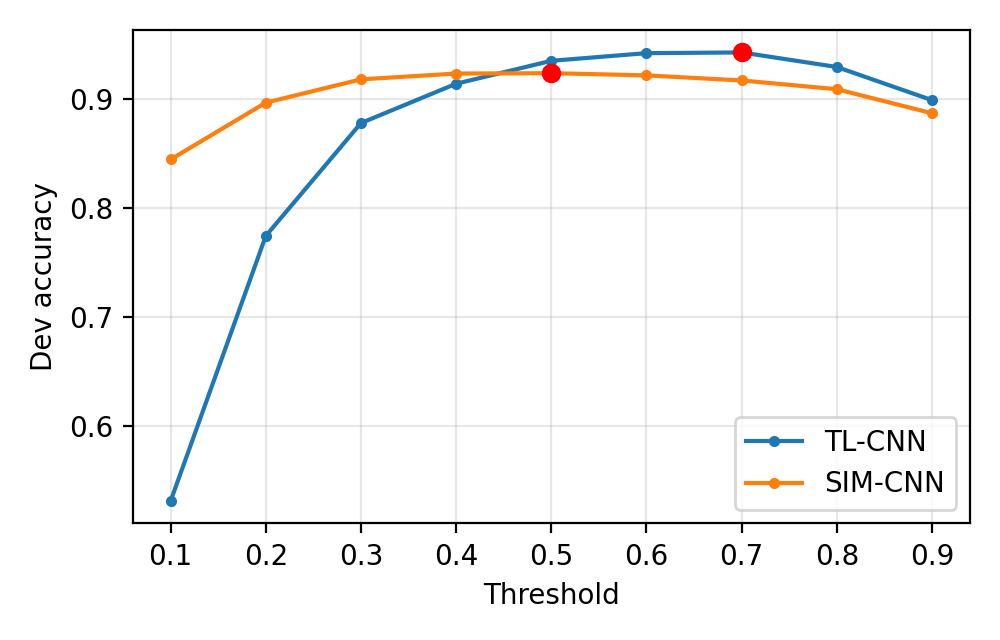

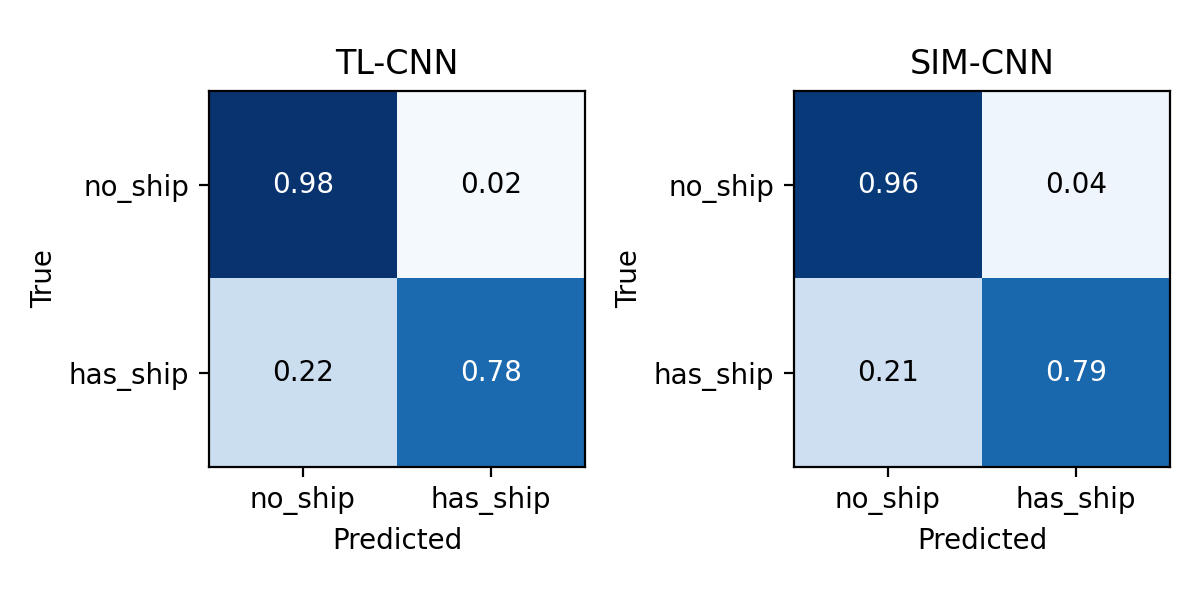

/kaggle/working/airbus_models.zip

In [21]:
# 6) package everything for download
import json, shutil, pandas as pd
from pathlib import Path
from IPython.display import Image, display, FileLink
out, mdir = Path(cfg.out), Path(cfg.model_dir)
for f in ["table1_test_accuracy.csv", "cv_scores.csv", "cnn_results.json"]:
    if (out / f).exists(): shutil.copy(out / f, mdir / f)
if (out / "figures").exists(): shutil.copytree(out / "figures", mdir / "figures", dirs_exist_ok=True)
shutil.make_archive("/kaggle/working/airbus_models", "zip", mdir)
for f in sorted(mdir.rglob("*")):
    if f.is_file(): print(f"{f.stat().st_size / 1e6:8.1f} MB  {f.relative_to(mdir)}")
r = json.load(open(out / "cnn_results.json"))["results"]
display(pd.DataFrame(r).T[["threshold", "test_acc", "test_acc_at_0_5", "precision", "recall", "specificity"]].round(3))
for f in sorted((out / "figures").glob("*.png")): display(Image(str(f)))
os.chdir("/kaggle/working"); display(FileLink("airbus_models.zip"))